# Lithology pipeline

Scan -> segmentation -> legend -> classification. The last cell runs everything on a list of pages and, when labels exist, reports boundary F1 and class IoU.

## 0. Setup

In [71]:
# %pip -q install torch scipy pandas pillow numpy matplotlib easyocr
import os, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from scipy.ndimage import label, center_of_mass
from scipy.signal import find_peaks
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment

Image.MAX_IMAGE_PIXELS = None

LOCAL_REPO = (
    Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
)
if LOCAL_REPO.name == "notebooks":
    LOCAL_REPO = LOCAL_REPO.parent
ROOT = Path(os.environ.get("HTB_ROOT", str(LOCAL_REPO / "data")))
GT_DIR = Path(
    os.environ.get("HTB_LABEL_DIR", str(ROOT / "test"))
)  # optional ground-truth label files
EXT_DIR = ROOT / "test" / "external_shared"  # external logs with exact CSV truth
OUTPUT_DIR = Path(os.environ.get("HTB_OUTPUT_DIR", str(ROOT / "predictions")))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(4, os.cpu_count() or 1))

# Segmentation rule parameters
H, WINDOW, MIN_GAP, INK_K = 8, 3, 2, 2.0


## 1. Load the page

In [72]:
# Crop a region of a very tall 1-bit or colour scan as RGB without decoding the whole page
def crop_rgb(img, box, scale=1.0, strip=2000):
    x0, y0, x1, y1 = box
    out = Image.new("RGB", (round((x1 - x0) * scale), round((y1 - y0) * scale)))
    for ys in range(y0, y1, strip):
        ye = min(ys + strip, y1)
        part = img.crop((x0, ys, x1, ye)).convert("RGB")
        top, bottom = round((ys - y0) * scale), round((ye - y0) * scale)
        if scale != 1.0:
            part = part.resize((out.width, max(1, bottom - top)), Image.Resampling.BOX)
        out.paste(part, (0, top))
    return out


# Image and annotation of a page
def page_paths(stem):
    # (image dir, annotation dir) pairs: the training dataset and the test pages
    for img_dir, ann_dir in (
        (ROOT / "dataset" / "images", ROOT / "dataset" / "bbox_annotation"),
        (ROOT / "test" / "images", ROOT / "test" / "annotations"),
        (EXT_DIR / "images", EXT_DIR / "bbox_annotation"),
    ):
        ann = ann_dir / f"{stem}.json"
        for ext in (".tif", ".tiff", ".png"):
            img = img_dir / f"{stem}{ext}"
            if img.is_file() and ann.is_file():
                return img, ann
    raise FileNotFoundError(f"no image + bbox_annotation pair for {stem} under {ROOT}")


# Load the interpreted lithology column as an RGB array and remember its y offset in the full image
def load_column(image_path, annotation_path):
    ann = json.loads(Path(annotation_path).read_text())
    x0, y0, x1, y1 = ann["bounding_boxes"]["interpreted_lithology_column"]
    if x0 >= x1 or y0 >= y1:
        raise ValueError(f"Empty lithology column in {annotation_path}")
    with Image.open(image_path) as img:
        return np.array(crop_rgb(img, (x0, y0, x1, y1))), y0


## 2. Segmentation

In [73]:
# Trim the thick border lines on either side of the column
def trim_borders(col):
    dark = col.mean(2, dtype=np.float32) < 100
    profile = dark.mean(0)
    idx = np.where(profile > 0.6)[0]
    mid = col.shape[1] // 2
    left, right = idx[idx < mid], idx[idx >= mid]
    x0 = left.max() + 3 if left.size else 0
    x1 = right.min() - 2 if right.size else col.shape[1]
    return col if x1 - x0 < 10 else col[:, x0:x1]


# Feature vector of one stripe: black-pixel density, component count, mean distance between components,
# mean component size, and the R, G, B of the original (non-black) background
STRIPE_FEATURE_NAMES = [
    "density",
    "n_components",
    "mean_dist",
    "mean_size",
    "bg_r",
    "bg_g",
    "bg_b",
]


def stripe_features(stripe, thresh=128, max_comp=2000):
    black = (
        stripe.mean(2, dtype=np.float32) < thresh
    )  # background -> white, ink -> black
    density = black.mean()
    bg = stripe[~black]
    bg_rgb = (
        bg.mean(0) / 255.0 if len(bg) else np.ones(3)
    )  # original background colour (white if no background)
    lab, n = label(black, structure=np.ones((3, 3)))  # 8-connected black components
    if n == 0:
        return np.array([density, 0, 0, 0, *bg_rgb], np.float32)
    ids = np.arange(1, n + 1)
    sizes = np.bincount(lab.ravel(), minlength=n + 1)[1:]
    if n > 1:
        cen = np.array(center_of_mass(black, lab, ids))
        if n > max_comp:  # keep pairwise distances cheap on very noisy stripes
            cen = cen[np.random.default_rng(0).choice(n, max_comp, replace=False)]
        mean_dist = pdist(cen).mean()
    else:
        mean_dist = 0.0
    return np.array([density, n, mean_dist, sizes.mean(), *bg_rgb], np.float32)


FEATURE_NAMES = STRIPE_FEATURE_NAMES


# Turn the column into a list of feature vectors, one per stripe of h rows (the last stripe may be shorter)
def column_to_vectors(col, h=H):
    col = trim_borders(col)
    return [stripe_features(col[s : s + h]) for s in range(0, len(col), h)]


# Raw feature matrix (n_stripes x 7): the stripe vectors stacked
def raw_stripe_features(col, h=H):
    return np.stack(column_to_vectors(col, h)).astype(np.float32)


# Z-score each feature over the column
def zscore(R):
    scale = R.std(0)
    scale[scale < 1e-6] = 1.0
    return (R - R.mean(0)) / scale


# Same features, z-scored (input to both boundary detectors)
def column_features(col, h=H):
    return zscore(raw_stripe_features(col, h))


# Turn boundary stripes into a table of bed tops and bottoms in full-image coordinates (n_rows = rows in the column)
def to_table(peaks, n_rows, y_offset, h=H):
    edges = np.concatenate([[0], np.sort(peaks) * h, [n_rows]]).astype(int)
    return pd.DataFrame(
        {"y_top": edges[:-1] + y_offset, "y_bottom": edges[1:] + y_offset}
    )


# Boundary rule: score each stripe by how much the average features change between the windows above and below it
def boundary_score(F, w=WINDOW):
    c = np.vstack([np.zeros((1, F.shape[1])), np.cumsum(F, 0)])
    n = len(F)
    ys = np.arange(w, n - w)
    above = (c[ys] - c[ys - w]) / w
    below = (c[ys + w] - c[ys]) / w
    score = np.zeros(n)
    score[ys] = np.linalg.norm(below - above, axis=1)
    return score


# Robust peak threshold: median + k * MAD, never below 1
def robust_threshold(s, k):
    med = np.median(s)
    mad = 1.4826 * np.median(np.abs(s - med))
    return max(med + k * max(mad, 1e-6), 1.0)


# Boundary stripes from the rule
def ink_boundaries(F, w=WINDOW, k=INK_K, gap=MIN_GAP):
    s = boundary_score(F, w)
    peaks, _ = find_peaks(s, height=robust_threshold(s, k), distance=gap)
    return peaks


# Column -> table of beds (y_top / y_bottom in full-image pixels)
def predict_segments(col, y_offset, F=None):
    F = column_features(col) if F is None else F
    beds = to_table(ink_boundaries(F), len(col), y_offset)
    return beds[beds.y_bottom > beds.y_top].reset_index(drop=True)


# The rule's intermediate values: boundary score per stripe, robust threshold, and the picked peaks (stripe indices)
def boundary_diagnostics(F, w=WINDOW, k=INK_K, gap=MIN_GAP):
    score = boundary_score(F, w)
    thr = robust_threshold(score, k)
    peaks, _ = find_peaks(score, height=thr, distance=gap)
    return score, thr, peaks


## 3. Legend

In [74]:
# Legend read text-first: OCR the labels, find the swatches around them, pair each swatch with its name
import cv2
from difflib import SequenceMatcher

NON_ROCK = re.compile(
    r"\b(core|dst|shoe|survey|mud (loss|gain)|lot|fit|rft|mdt|sidewall|casing|fossils?|"
    r"foraminifera|diatoms?|gas|oil|show|cuttings|sample|bit|trip)\b",
    re.I,
)
ROCK_WORDS = (
    "clay",
    "claystone",
    "mudstone",
    "shale",
    "shaly",
    "grey",
    "gray",
    "brown",
    "green",
    "red",
    "black",
    "calcareous",
    "argillaceous",
    "silt",
    "silty",
    "siltstone",
    "sand",
    "sandy",
    "sandstone",
    "and",
    "with",
    "conglomerate",
    "breccia",
    "limestone",
    "limy",
    "dolomite",
    "dolomitic",
    "chalk",
    "marl",
    "halite",
    "salt",
    "anhydrite",
    "gypsum",
    "sylvite",
    "potash",
    "coal",
    "lignite",
    "bitumen",
    "chert",
    "tuff",
    "volcanic",
    "ash",
    "basalt",
    "granite",
    "cement",
    "igneous",
    "metamorphic",
)

WORD_MATCH_MIN = 0.75
MIN_PATTERN_INK = 0.03
Box = tuple
LABEL_MIN_CONF = 0.3
LABEL_BUDGET_S = 600.0
DEFAULT_TEXT_H = 18.0
SWATCH_H = (0.9, 5.0)
SWATCH_W = (1.2, 12.0)
MAX_ASPECT = 8.0
MIN_FILL = 0.55
MIN_INK = 0.01
SIZE_TOL = 0.35
MAX_PAIR_COST = 3.0
NAME_MATCH_MIN = 0.8
LOW_SCORE = 0.6


def is_rock(label: str | None) -> bool:
    """False for drilling and sampling symbols, which are never lithology candidates."""
    return not NON_ROCK.search(label or "")


def box_iou(a, b) -> float:
    """Intersection over union of two boxes."""
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - ix * iy
    return ix * iy / union if union else 0.0


def _xyxy(box) -> tuple[float, float, float, float]:
    """Axis-aligned (x0, y0, x1, y1) from a flat box or a list of corner points."""
    arr = np.asarray(box, dtype=float)
    if arr.ndim == 1 and arr.size == 4:
        return tuple(arr)
    pts = arr.reshape(-1, 2)
    return pts[:, 0].min(), pts[:, 1].min(), pts[:, 0].max(), pts[:, 1].max()


def _centre(b) -> np.ndarray:
    """Centre point of a box."""
    return np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2])


def _anchor_points(b) -> np.ndarray:
    """Left-middle, right-middle, centre, top-centre and bottom-centre of a box, the candidate label anchors."""
    cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    return np.array([[b[0], cy], [b[2], cy], [cx, cy], [cx, b[1]], [cx, b[3]]])


def _gap(a, b) -> float:
    """Shortest distance between the edges of two boxes, 0 when they touch or overlap."""
    dx = max(0.0, b[0] - a[2], a[0] - b[2])
    dy = max(0.0, b[1] - a[3], a[1] - b[3])
    return float(np.hypot(dx, dy))


def _text_lines(gray, warnings):
    """OCR text lines of the legend crop with at least two letters; None when easyocr is unavailable."""
    try:
        import easyocr
    except ImportError:
        warnings.append(
            "easyocr not installed (pip install easyocr): swatches will be named legend_<id>"
        )
        return None
    if not hasattr(_text_lines, "reader"):
        _text_lines.reader = easyocr.Reader(
            ["en"],
            gpu=torch.cuda.is_available(),
            verbose=False,
            model_storage_directory=str(OUTPUT_DIR / "ocr_models"),
            user_network_directory=str(OUTPUT_DIR / "ocr_networks"),
        )
    for scale in (1.0, 2.0):
        img = (
            gray
            if scale == 1.0
            else cv2.resize(
                gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC
            )
        )
        lines = [
            (tuple(v / scale for v in _xyxy(box)), text.strip())
            for box, text, conf in _text_lines.reader.readtext(img)
            if conf >= LABEL_MIN_CONF and sum(c.isalpha() for c in text) >= 2
        ]
        if lines:
            return lines
    return []


def _text_height(lines) -> float:
    """Median text line height, the legend's scale reference."""
    return (
        float(np.median([b[3] - b[1] for b, _ in lines])) if lines else DEFAULT_TEXT_H
    )


def _group_labels(lines, text_h: float) -> list[tuple[tuple[float, ...], str]]:
    """Join words on one line and the stacked lines of one name (left-aligned or centred) into label boxes."""
    key = lambda l: (round((l[0][1] + l[0][3]) / 2 / (0.5 * text_h)), l[0][0])
    labels: list[list] = []
    for box, text in sorted(lines, key=key):
        for lab in labels:
            x0, y0, x1, y1 = lab[0]
            same_line = (
                abs((box[1] + box[3]) / 2 - (y0 + y1) / 2) < 0.5 * text_h
                and -0.2 * text_h < box[0] - x1 < 1.2 * text_h
            )
            aligned = (
                abs(box[0] - x0) < 0.6 * text_h
                or abs((box[0] + box[2]) / 2 - (x0 + x1) / 2) < 0.6 * text_h
            )
            next_line = aligned and 0 <= box[1] - y1 < 0.6 * text_h
            if same_line or next_line:
                lab[0] = (
                    min(x0, box[0]),
                    min(y0, box[1]),
                    max(x1, box[2]),
                    max(y1, box[3]),
                )
                lab[1] = f"{lab[1]} {text}"
                break
        else:
            labels.append([box, text])
    return [(tuple(b), t) for b, t in labels]


def _fix_word(word: str) -> tuple[str, bool]:
    """Snap one OCR word to the rock vocabulary after undoing I/l/1 confusions; the flag says whether it matched."""
    w = word.strip(".,:;-_|()")
    if not w:
        return "", True
    inner = w[1:]
    variants = {
        w,
        w[0] + inner.replace("l", "i"),
        w[0] + inner.replace("I", "i"),
        w[0] + inner.replace("1", "i"),
        w[0] + inner.replace("I", "i").replace("l", "i"),
    }
    score = lambda v, r: SequenceMatcher(None, v.lower(), r).ratio()
    ratio, best = max((score(v, r), r) for v in variants for r in ROCK_WORDS)
    if ratio < WORD_MATCH_MIN:
        return w, False
    return (best.capitalize() if w[0].isupper() else best), True


def _clean_name(text: str) -> tuple[str, bool]:
    """Tidy an OCR name word by word against the rock vocabulary; the flag is False for unknown rock names."""
    tokens = text.replace("|", "l").split()
    merged = []
    for tok in tokens:
        if merged and len(merged[-1]) == 1 and merged[-1].isalpha():
            merged[-1] += tok
        else:
            merged.append(tok)
    fixed = [_fix_word(t) for t in merged]
    words = [w for w, _ in fixed if w]
    name = " ".join(words).strip()
    if not name:
        return "", False
    name = name[0].upper() + name[1:]
    known = all(ok for _, ok in fixed) or not is_rock(name)
    return name, known


def _has_pattern(free: np.ndarray, b: Box) -> bool:
    """True when the inside of a box (frame excluded) holds enough ink to be a real swatch."""
    w, h = b[2] - b[0], b[3] - b[1]
    mx, my = max(2, int(0.15 * w)), max(2, int(0.15 * h))
    inner = free[b[1] + my : b[3] - my, b[0] + mx : b[2] - mx]
    return inner.size > 0 and inner.mean() >= MIN_PATTERN_INK


def _ink(rgb: np.ndarray, text_h: float) -> np.ndarray:
    """Dark ink from an adaptive threshold plus coloured fills measured against the paper colour."""
    gray = rgb.mean(2).astype(np.uint8)
    block = int(max(15, 2 * round(1.5 * text_h) + 1))
    dark = (
        cv2.adaptiveThreshold(
            gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, block, 15
        )
        > 0
    )
    paper = np.percentile(rgb.reshape(-1, 3), 95, axis=0)
    colour = (paper - rgb.astype(np.int16)).max(2) > 40
    return dark | colour


def _mask_text(ink: np.ndarray, labels, text_h: float) -> np.ndarray:
    """Ink with every label box (plus a margin) erased."""
    free = ink.copy()
    pad = int(round(0.2 * text_h))
    for (x0, y0, x1, y1), _ in labels:
        free[
            max(int(y0) - pad, 0) : int(y1) + pad, max(int(x0) - pad, 0) : int(x1) + pad
        ] = False
    return free


def _swatch_mask(free: np.ndarray, text_h: float) -> np.ndarray:
    """Text-free ink without long table rules, closed and filled so each swatch is one solid region."""
    u8 = free.astype(np.uint8)
    h_rule = np.ones((1, int(SWATCH_W[1] * text_h) + 1), np.uint8)
    v_rule = np.ones((int(SWATCH_H[1] * text_h) + 1, 1), np.uint8)
    rules = (
        cv2.morphologyEx(u8, cv2.MORPH_OPEN, h_rule)
        | cv2.morphologyEx(u8, cv2.MORPH_OPEN, v_rule)
    ) > 0
    k = max(3, int(round(0.4 * text_h)) | 1)
    closed = (
        cv2.morphologyEx(
            (free & ~rules).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((k, k), np.uint8)
        )
        > 0
    )
    return ndimage.binary_fill_holes(closed)


def _candidates(mask: np.ndarray, free: np.ndarray, text_h: float) -> list[Box]:
    """Regions of swatch size (relative to the text height) that are box-shaped and hold some ink."""
    lab, _ = ndimage.label(mask)
    out = []
    for i, sl in enumerate(ndimage.find_objects(lab), 1):
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        w, h = x1 - x0, y1 - y0
        if not (
            SWATCH_W[0] * text_h <= w <= SWATCH_W[1] * text_h
            and SWATCH_H[0] * text_h <= h <= SWATCH_H[1] * text_h
        ):
            continue
        if (
            0.7 <= w / h <= MAX_ASPECT
            and (lab[sl] == i).mean() >= MIN_FILL
            and free[sl].mean() >= MIN_INK
        ):
            out.append((x0, y0, x1, y1))
    return out


def _fixed_size_swatches(
    rgb: np.ndarray, min_w=25, max_w=200, min_h=15, max_h=120
) -> list[Box]:
    """Fallback detector: dark-framed boxes plus solid colour rectangles of fixed pixel size."""
    rgb = rgb.astype(np.int16)

    def candidates(mask):
        lines = ndimage.binary_opening(
            mask, np.ones((1, max_w + 1))
        ) | ndimage.binary_opening(mask, np.ones((max_h + 1, 1)))
        lab, _ = ndimage.label(mask & ~lines)
        for i, sl in enumerate(ndimage.find_objects(lab), 1):
            y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
            w, h = x1 - x0, y1 - y0
            if (
                min_w <= w <= max_w
                and min_h <= h <= max_h
                and 0.7 <= w / h <= MAX_ASPECT
            ):
                yield lab[y0:y1, x0:x1] == i, (x0, y0, x1, y1)

    framed = []
    for m, b in candidates(rgb.mean(2) < 110):
        sides = [
            max(m[k].mean() for k in (0, 1, 2)),
            max(m[-k].mean() for k in (1, 2, 3)),
            max(m[:, k].mean() for k in (0, 1, 2)),
            max(m[:, -k].mean() for k in (1, 2, 3)),
        ]
        if min(sides) >= 0.8:
            framed.append(b)
    solid = [
        b
        for m, b in candidates((255 - rgb).max(2) > 40)
        if ndimage.binary_fill_holes(m).mean() >= 0.9
    ]
    return framed + [b for b in solid if not any(box_iou(b, f) > 0.3 for f in framed)]


def _outermost(boxes: list[Box]) -> list[Box]:
    """Boxes not contained in another box."""
    return [
        b
        for b in boxes
        if not any(
            o != b and o[0] <= b[0] and o[1] <= b[1] and o[2] >= b[2] and o[3] >= b[3]
            for o in boxes
        )
    ]


def _pair(
    boxes: list[Box], labels, text_h: float
) -> tuple[dict[int, int], int | None, np.ndarray | None]:
    """One-to-one swatch-to-label assignment around the legend's typical label offset; returns pairs, anchor and offset."""
    if not boxes or not labels:
        return {}, None, None
    gap = np.array([[_gap(s, l) for l, _ in labels] for s in boxes])
    near_label, near_box = gap.argmin(1), gap.argmin(0)
    mutual = [(i, int(j)) for i, j in enumerate(near_label) if near_box[j] == i]
    anchor, typical = None, None
    if len(mutual) >= 2:
        spreads = []
        for k in range(3):
            off = np.array(
                [_anchor_points(labels[j][0])[k] - _centre(boxes[i]) for i, j in mutual]
            )
            med = np.median(off, 0)
            spreads.append(
                (float(np.median(np.linalg.norm(off - med, axis=1))), k, med)
            )
        _, anchor, typical = min(spreads, key=lambda s: (s[0], s[1]))
        cost = (
            np.array(
                [
                    [
                        np.linalg.norm(_anchor_points(l)[anchor] - _centre(s) - typical)
                        for l, _ in labels
                    ]
                    for s in boxes
                ]
            )
            / text_h
        )
    else:
        cost = gap / text_h
    rows, cols = linear_sum_assignment(cost)
    return (
        {int(r): int(c) for r, c in zip(rows, cols) if cost[r, c] <= MAX_PAIR_COST},
        anchor,
        typical,
    )


def _recover(
    boxes: list[Box], labels, pairs, anchor, typical, free: np.ndarray
) -> tuple[list[Box], dict[int, int]]:
    """Add a typical-size swatch where an unpaired, recognised label expects one and there is ink."""
    if anchor is None or not boxes:
        return boxes, pairs
    w = float(np.median([b[2] - b[0] for b in boxes]))
    h = float(np.median([b[3] - b[1] for b in boxes]))
    height, width = free.shape
    boxes, pairs = list(boxes), dict(pairs)
    used = set(pairs.values())
    for j, (lbox, text) in enumerate(labels):
        if j in used or not _clean_name(text)[1]:
            continue
        cx, cy = _anchor_points(lbox)[anchor] - typical
        b = (
            int(round(cx - w / 2)),
            int(round(cy - h / 2)),
            int(round(cx + w / 2)),
            int(round(cy + h / 2)),
        )
        if b[0] < 0 or b[1] < 0 or b[2] > width or b[3] > height:
            continue
        if free[b[1] : b[3], b[0] : b[2]].mean() < MIN_INK or any(
            box_iou(b, o) > 0.3 for o in boxes
        ):
            continue
        pairs[len(boxes)] = j
        boxes.append(b)
    return boxes, pairs


def _keep(
    boxes: list[Box], pairs: dict[int, int], free: np.ndarray
) -> tuple[list[Box], dict[int, int]]:
    """Paired boxes plus unpaired boxes of the typical size that contain a pattern, with pairs reindexed."""
    if len(boxes) >= 3:
        w = np.median([b[2] - b[0] for b in boxes])
        h = np.median([b[3] - b[1] for b in boxes])
        typical = lambda b: (
            abs((b[2] - b[0]) / w - 1) <= SIZE_TOL
            and abs((b[3] - b[1]) / h - 1) <= SIZE_TOL
        )
    else:
        typical = lambda b: True
    keep = [
        i
        for i, b in enumerate(boxes)
        if i in pairs or (typical(b) and _has_pattern(free, b))
    ]
    return [boxes[i] for i in keep], {
        n: pairs[i] for n, i in enumerate(keep) if i in pairs
    }


def _reading_order(boxes: list[Box]) -> list[int]:
    """Indices of boxes in reading order: rows by centre height, then left to right."""
    if not boxes:
        return []
    h = float(np.median([b[3] - b[1] for b in boxes]))
    rows: list[list[int]] = []
    ref = None
    for i in sorted(range(len(boxes)), key=lambda i: (boxes[i][1] + boxes[i][3]) / 2):
        c = (boxes[i][1] + boxes[i][3]) / 2
        if ref is None or c - ref > 0.5 * h:
            rows.append([])
            ref = c
        rows[-1].append(i)
    return [i for row in rows for i in sorted(row, key=lambda i: boxes[i][0])]


def _score(boxes: list[Box], names: dict[int, tuple[str, bool]], warnings) -> None:
    """Warn when too few swatches are paired or too few names are recognised."""
    if boxes and len(names) / len(boxes) < LOW_SCORE:
        warnings.append("legend_unpaired_swatches")
    if names and np.mean([known for _, known in names.values()]) < LOW_SCORE:
        warnings.append("legend_unknown_names")


def _analyse(img, legend_box, warnings):
    """Swatch boxes in full-image pixels and reading order, with their names, found text-first."""
    lx0, ly0, _, _ = legend_box
    rgb = np.array(crop_rgb(img, legend_box))
    lines = _text_lines(rgb.mean(2).astype(np.uint8), warnings) or []
    text_h = _text_height(lines)
    labels = _group_labels(lines, text_h)
    free = _mask_text(_ink(rgb, text_h), labels, text_h)
    boxes = _outermost(_candidates(_swatch_mask(free, text_h), free, text_h))
    if len(boxes) < 2:
        boxes = _outermost(_fixed_size_swatches(rgb))
        if boxes:
            warnings.append("legend_fixed_size_fallback")
    pairs, anchor, typical = _pair(boxes, labels, text_h)
    found = len(boxes)
    boxes, pairs = _recover(boxes, labels, pairs, anchor, typical, free)
    if len(boxes) > found:
        warnings.append("legend_recovered_swatches")
    boxes, pairs = _keep(boxes, pairs, free)
    names = {i: _clean_name(labels[j][1]) for i, j in pairs.items()}
    _score(boxes, names, warnings)
    order = _reading_order(boxes)
    full = [
        (int(b[0] + lx0), int(b[1] + ly0), int(b[2] + lx0), int(b[3] + ly0))
        for b in boxes
    ]
    return [full[i] for i in order], [
        names[i][0] if i in names else None for i in order
    ]


# Legend of a page: detected swatches + OCR names
def detect_swatches(img, legend_box):
    return _analyse(img, legend_box, [])[0]


def load_legend(img, legend_box, ocr=True):
    warnings = []
    boxes, names = _analyse(img, legend_box, warnings)
    if not ocr:
        names = [None] * len(boxes)
    for w in dict.fromkeys(warnings):
        print(f"  legend warning: {w}")
    return pd.DataFrame(
        [
            {"legend_id": i, "lithology": n or f"legend_{i}", "box": b}
            for i, (b, n) in enumerate(zip(boxes, names))
        ],
        columns=["legend_id", "lithology", "box"],
    )


# Swatch interior with the frame removed
def swatch_pixels(img, box, inset=3):
    x0, y0, x1, y1 = box
    return np.array(
        img.crop((x0 + inset, y0 + inset, x1 - inset, y1 - inset)).convert("RGB")
    )

## 4. Classification

In [75]:
RUN_BINS = np.array([1, 2, 3, 4, 6, 9, 13, 21, 10**6])  # run-length bin edges (px)
W_COLOR, W_INK, W_TEXTURE, TEXTURE_FULL_PX = 1 / 10, 4.0, 1.0, 24


def srgb_to_lab(rgb):
    c = np.asarray(rgb, np.float64) / 255.0
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    xyz = (
        c
        @ np.array(
            [
                [0.4124, 0.3576, 0.1805],
                [0.2126, 0.7152, 0.0722],
                [0.0193, 0.1192, 0.9505],
            ]
        ).T
    )
    xyz = xyz / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


# Length-weighted histogram of runs of True along each row
def run_hist(mask):
    m = np.pad(mask.astype(np.int8), ((0, 0), (1, 1)))
    d = np.diff(m, axis=1)
    lengths = np.where(d == -1)[1] - np.where(d == 1)[1]
    h = np.histogram(lengths, bins=RUN_BINS, weights=lengths)[0].astype(np.float64)
    return h / h.sum() if h.sum() else h


# Colour + texture descriptor of an RGB patch (swatch interior or rows of the column)
def describe(rgb):
    rgb = np.asarray(rgb)
    dark = rgb.mean(2) < 128
    light = rgb[~dark]
    return {
        "lab": srgb_to_lab(np.median(light, 0) if len(light) else np.zeros(3)),
        "ink": float(dark.mean()),
        "h_dark": run_hist(dark),
        "v_dark": run_hist(dark.T),
        "h_gap": run_hist(~dark),
        "v_gap": run_hist(~dark.T),
        "rows": rgb.shape[0],
    }


# Distance between a segment and a swatch; vertical runs count less in thin segments (they are cut short)
def descriptor_distance(seg, sw):
    tv = lambda k: 0.5 * np.abs(seg[k] - sw[k]).sum()
    v_weight = min(1.0, seg["rows"] / TEXTURE_FULL_PX)
    d_tex = (tv("h_dark") + tv("h_gap") + v_weight * (tv("v_dark") + tv("v_gap"))) / 4
    return (
        np.linalg.norm(seg["lab"] - sw["lab"]) * W_COLOR
        + abs(seg["ink"] - sw["ink"]) * W_INK
        + W_TEXTURE * d_tex
    )


# Pseudo-swatch for empty white rows
NB = len(RUN_BINS) - 1
BLANK = {
    "lab": srgb_to_lab([255, 255, 255]),
    "ink": 0.0,
    "h_dark": np.zeros(NB),
    "v_dark": np.zeros(NB),
    "h_gap": np.eye(NB)[-1],
    "v_gap": np.eye(NB)[-1],
    "rows": 1,
}


# Candidate prototypes: blank first, then every rock swatch of the legend
def prototypes(legend, img, rocks_only=True):
    leg = (
        legend.loc[legend.lithology.map(is_rock).astype(bool)] if rocks_only else legend
    )
    return [(-1, "blank", BLANK)] + [
        (r.legend_id, r.lithology, describe(swatch_pixels(img, r.box)))
        for r in leg.itertuples()
    ]


In [76]:
SPLIT_WINDOW, SPLIT_MIN_RUN = (
    16,
    3,
)  # window height (px), min consecutive windows for a split-off lithology


# Split segments whose windows clearly match different swatches (boundaries Section 2 missed)
def split_mixed(
    segments, col, y_offset, protos, win=SPLIT_WINDOW, min_run=SPLIT_MIN_RUN
):
    cols = trim_borders(col)
    rows = []
    for s in segments.itertuples():
        a = s.y_top - y_offset
        n = (s.y_bottom - s.y_top) // win
        if n < 2 * min_run:
            rows.append((s.y_top, s.y_bottom))
            continue
        windows = [describe(cols[a + i * win : a + (i + 1) * win]) for i in range(n)]
        lab = [
            int(np.argmin([descriptor_distance(w, p) for _, _, p in protos]))
            for w in windows
        ]
        runs = []  # [label, first window, n windows]
        for i, l in enumerate(lab):
            if runs and runs[-1][0] == l:
                runs[-1][2] += 1
            else:
                runs.append([l, i, 1])
        kept = [r for r in runs if r[2] >= min_run] or [max(runs, key=lambda r: r[2])]
        starts = [r[1] for k, r in enumerate(kept) if k == 0 or r[0] != kept[k - 1][0]][
            1:
        ]
        edges = [s.y_top] + [s.y_top + i * win for i in starts] + [s.y_bottom]
        rows += list(zip(edges[:-1], edges[1:]))
    return pd.DataFrame(
        {
            "segment": range(len(rows)),
            "y_top": [r[0] for r in rows],
            "y_bottom": [r[1] for r in rows],
        }
    )


# Name every segment with its closest prototype; margin = gap to the runner-up (small = unsure)
def name_segments(segments, col, y_offset, protos, trim=2):
    cols = trim_borders(col)
    out = []
    for s in segments.itertuples():
        a, b = s.y_top - y_offset, s.y_bottom - y_offset
        if b - a > 4 * trim:
            a, b = a + trim, b - trim
        d = describe(cols[a:b])
        dist = np.array([descriptor_distance(d, p) for _, _, p in protos])
        order = np.argsort(dist)
        out.append(
            {
                "legend_id": protos[order[0]][0],
                "lithology": protos[order[0]][1],
                "distance": dist[order[0]],
                "margin": dist[order[1]] - dist[order[0]] if len(order) > 1 else 0.0,
            }
        )
    return pd.concat(
        [segments[["y_top", "y_bottom"]].reset_index(drop=True), pd.DataFrame(out)],
        axis=1,
    )


# Merge neighbouring segments with the same legend entry into lithology layers
def merge_named(named):
    rows = []
    for r in named.itertuples():
        if (
            rows
            and rows[-1]["legend_id"] == r.legend_id
            and rows[-1]["y_bottom"] == r.y_top
        ):
            rows[-1]["y_bottom"] = r.y_bottom
            rows[-1]["n_segments"] += 1
        else:
            rows.append(
                {
                    "y_top": r.y_top,
                    "y_bottom": r.y_bottom,
                    "legend_id": r.legend_id,
                    "lithology": r.lithology,
                    "n_segments": 1,
                }
            )
    return pd.DataFrame(rows)


# Section 2 segments of a column -> named lithology layers
def lithology_layers(segments, col, y_offset, legend, img, split=True):
    protos = prototypes(legend, img)
    if split:
        segments = split_mixed(segments, col, y_offset, protos)
    named = name_segments(segments, col, y_offset, protos)
    return named, merge_named(named)


## 5. Pipeline, metrics and plots

In [77]:
# Full pipeline for one page -> dict with column, beds, legend and named lithology layers (blank layers have legend_id -1)
def run_pipeline(stem, verbose=True):
    img_path, ann_path = page_paths(stem)
    boxes = json.loads(ann_path.read_text())["bounding_boxes"]
    col, y_off = load_column(img_path, ann_path)
    if verbose:
        print(f"  1. column {col.shape}, y offset {y_off}")
    raw = raw_stripe_features(col)  # stripe feature vectors (n_stripes x 7)
    F = zscore(raw)
    segments = predict_segments(col, y_off, F)
    score, thr, peaks = boundary_diagnostics(F)
    if verbose:
        print(f"  2. {len(segments)} segments")
    with Image.open(img_path) as img:
        legend = load_legend(img, boxes["lithology_legend"])
        if verbose:
            print(f"  3. {len(legend)} legend entries: {list(legend.lithology)}")
        named, layers = lithology_layers(segments, col, y_off, legend, img)
        colors = {
            r.legend_id: np.median(swatch_pixels(img, r.box).reshape(-1, 3), 0) / 255
            for r in legend.itertuples()
        }
    if verbose:
        print(f"  4. {len(named)} named segments -> {len(layers)} lithology layers")
    return dict(
        stem=stem,
        col=col,
        y_offset=y_off,
        segments=segments,
        legend=legend,
        layers=layers,
        colors=colors,
        features=raw,
        score=score,
        threshold=thr,
        peaks=peaks,
    )


# Ground truth of a page (None if there is no label file with layers)
def load_gt(stem):
    csv = EXT_DIR / "truth" / f"{stem}.csv"
    if csv.exists():  # external logs: top_y,bottom_y,lithology rows
        t = pd.read_csv(csv)
        return [
            (int(a), int(b), str(n))
            for a, b, n in zip(t.top_y, t.bottom_y, t.lithology)
        ] or None
    p = GT_DIR / f"{stem}.json"
    if not p.exists():
        return None
    layers = json.loads(p.read_text()).get("layers") or []
    if not layers:
        return None
    return [
        (
            l["top_px"],
            l["bottom_px"],
            max(l["composition"], key=lambda c: c["proportion"])["type"],
        )
        for l in layers
    ]


def norm(t):
    return re.sub(r"[^a-z0-9]+", " ", (t or "").lower()).strip()


# Predicted layers as (top, bottom, name); blank layers are left out
def pred_layers(res):
    return [
        (int(r.y_top), int(r.y_bottom), r.lithology)
        for r in res["layers"].itertuples()
        if r.legend_id >= 0
    ]


# ---- Boundary F1: Hungarian one-to-one matching of layer edges within +-tol px ----
def boundary_set(layers):
    return np.array(sorted({int(round(v)) for l in layers for v in l[:2]}))


def boundary_match(gt_b, pred_b, tol):
    if len(gt_b) == 0 or len(pred_b) == 0:
        return 0
    d = np.abs(gt_b[:, None] - pred_b[None, :])
    r, c = linear_sum_assignment(np.where(d <= tol, d, 10**6))
    return int((d[r, c] <= tol).sum())


def boundary_f1(gt, pred, tols=(3, 5, 10)):
    g, p = boundary_set(gt), boundary_set(pred)
    out = {}
    for t in tols:
        tp = boundary_match(g, p, t)
        pr, rc = tp / max(len(p), 1), tp / max(len(g), 1)
        out[t] = dict(
            precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc) if tp else 0.0
        )
    return out, len(g), len(p)


# ---- Class IoU: pixel-wise, classes compared by normalised name, background (uncovered rows) excluded from the mean ----
def rows_by_name(layers, lo, hi):
    out = np.full(hi - lo, "background", dtype=object)
    for top, bot, name in sorted(layers):
        out[max(top - lo, 0) : max(bot - lo, 0)] = norm(name)
    return out


def class_iou(gt, pred):
    lo = min(l[0] for l in gt + pred)
    hi = max(l[1] for l in gt + pred)
    g, p = rows_by_name(gt, lo, hi), rows_by_name(pred, lo, hi)
    ious = {}
    for c in sorted((set(g) | set(p)) - {"background"}):
        union = ((g == c) | (p == c)).sum()
        ious[c] = dict(
            iou=((g == c) & (p == c)).sum() / union,
            gt_rows=int((g == c).sum()),
            pred_rows=int((p == c).sum()),
        )
    in_gt = [v["iou"] for v in ious.values() if v["gt_rows"] > 0]
    return (
        ious,
        float(np.mean(in_gt)) if in_gt else float("nan"),
        float((g == p).mean()),
    )


# ---- Plot: the column cut into lines of line_rows rows (depth runs left -> right). Each line shows the scan, the predicted
# and (if available) true lithology bands (coloured by legend swatch, red / green = predicted / true boundaries) and, below,
# the boundary score (orange dashed = robust threshold, red triangles = picked peaks) and one small plot per feature channel aligned with the rows (one value per H-px stripe) ----
CHANNEL_COLORS = dict(bg_r="tab:red", bg_g="tab:green", bg_b="tab:blue")


def plot_page(res, gt=None, line_rows=2500, width=20, channels=True):
    col, y_off, pred, R = res["col"], res["y_offset"], pred_layers(res), res["features"]
    n = len(col)
    extra = plt.get_cmap("tab20")
    # Swatch colour, unless the swatch is (near) white / grey (black-and-white pattern swatches), then a distinct palette colour
    name_color = {}
    for r in res["legend"].itertuples():
        c = np.asarray(res["colors"][r.legend_id], float)
        if c.min() > 0.85 or c.max() - c.min() < 0.08:
            c = np.array(extra((2 * len(name_color)) % 20)[:3])
        name_color[norm(r.lithology)] = c
    for _, _, nm in gt or []:
        name_color.setdefault(norm(nm), np.array(extra(len(name_color) % 20)[:3]))
    name_color["background"] = np.ones(3)

    def band(layers, a, b):
        names = rows_by_name(layers, y_off + a, y_off + b)
        return np.array([name_color.get(x, np.full(3, 0.5)) for x in names])[None]

    tracks = [("predicted", pred, "red")] + ([("true", gt, "green")] if gt else [])
    nch = R.shape[1] if channels else 0
    per_line = [2.2, *[0.7] * len(tracks), 1.2, *[0.8] * nch]
    lines = range(0, n, line_rows)
    fig, axes = plt.subplots(
        len(lines) * len(per_line),
        1,
        figsize=(width, len(lines) * (sum(per_line) * 0.6 + 0.4) + 1),
        gridspec_kw={
            "height_ratios": per_line * len(lines),
            "hspace": 0.12,
            "top": 0.97,
            "bottom": 0.03,
        },
    )
    axes = np.atleast_1d(axes)
    for li, a in enumerate(lines):
        b = min(a + line_rows, n)
        x0, x1 = y_off + a, y_off + a + line_rows
        ax = axes[li * len(per_line)]
        ax.imshow(
            col[a:b].transpose(1, 0, 2),
            aspect="auto",
            extent=(y_off + a, y_off + b, 0, 1),
            interpolation="nearest",
        )
        ax.set_yticks([])
        ax.set_xlim(x0, x1)
        ax.tick_params(labelsize=7)
        for k, (title, layers, c) in enumerate(tracks):
            ax2 = axes[li * len(per_line) + 1 + k]
            ax2.imshow(
                band(layers, a, b),
                aspect="auto",
                extent=(y_off + a, y_off + b, 0, 1),
                interpolation="nearest",
            )
            for y in boundary_set(layers):
                if x0 <= y <= y_off + b:
                    ax2.axvline(y, color=c, lw=0.7)
            ax2.set_xlim(x0, x1)
            ax2.set_yticks([0.5], [title], fontsize=8)
            ax2.set_xticks([])
        # boundary score, robust threshold (median + INK_K x MAD) and the picked peaks
        axs = axes[li * len(per_line) + 1 + len(tracks)]
        sc, s0, s1 = res["score"], a // H, min(-(-b // H), len(res["score"]))
        axs.step(
            y_off + np.arange(s0, s1) * H, sc[s0:s1], where="post", lw=0.8, color="k"
        )
        axs.axhline(res["threshold"], color="orange", ls="--", lw=1)
        pk = res["peaks"][(res["peaks"] >= s0) & (res["peaks"] < s1)]
        axs.plot(y_off + pk * H, sc[pk], "v", color="red", ms=4)
        axs.set_xlim(x0, x1)
        axs.set_ylim(0, max(sc.max(), res["threshold"]) * 1.05)
        axs.set_yticks([])
        axs.set_ylabel(
            "boundary score", rotation=0, ha="right", va="center", fontsize=7
        )
        axs.tick_params(labelsize=6)
        axs.set_xticks([])
        for k in range(nch):
            ax3 = axes[li * len(per_line) + 2 + len(tracks) + k]
            s0, s1 = a // H, min(-(-b // H), len(R))
            ax3.step(
                y_off + np.arange(s0, s1 + 1) * H,
                np.r_[R[s0:s1, k], R[s1 - 1, k]],
                where="post",
                lw=0.8,
                color=CHANNEL_COLORS.get(STRIPE_FEATURE_NAMES[k], "k"),
            )
            for (
                tr
            ) in tracks:  # predicted boundaries as a faint guide through every channel
                if tr[0] == "predicted":
                    for y in boundary_set(tr[1]):
                        if x0 <= y <= y_off + b:
                            ax3.axvline(y, color="red", lw=0.4, alpha=0.4)
            ax3.set_xlim(x0, x1)
            ax3.set_yticks([])
            ax3.set_ylabel(
                STRIPE_FEATURE_NAMES[k], rotation=0, ha="right", va="center", fontsize=7
            )
            ax3.tick_params(labelsize=6)
            if k < nch - 1:
                ax3.set_xticks([])
    used = {norm(l[2]) for l in pred + (gt or [])}
    fig.legend(
        [
            plt.Rectangle((0, 0), 1, 1, fc=name_color[u], ec="k", lw=0.5)
            for u in sorted(used)
        ],
        sorted(used),
        loc="lower center",
        ncol=min(len(used), 6),
        bbox_to_anchor=(0.5, 0.0),
        fontsize=9,
    )
    fig.suptitle(
        f"{res['stem']}  (rows are image y; {line_rows} rows per line)", y=0.99
    )
    plt.show()


## 6. Run on a list of pages

== 60807402860000_gb506#2_tvd_mudlog
  1. column (8418, 47, 3), y offset 1206
  2. 43 segments


c:\Users\Benedek\!_Extr\HTB_final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  3. 25 legend entries: ['Clay Shale', 'Shale', 'Siltstone', 'Sandstone', 'Chert', 'Limestone', 'Dolomite', 'Halite', 'Anhydrite', 'Gypsum', 'Test', 'Core', 'DST', 'legend_13', 'Iaminate Beddings', 'Fossils in genera', 'Mud OSS', 'Mud gain', 'Deviation survey', 'Plastic Clay', 'Shoe', 'Huile', 'Gaz', 'Sidewall Core', 'Diatomite']
  4. 43 named segments -> 35 lithology layers
  no ground truth -> metrics skipped


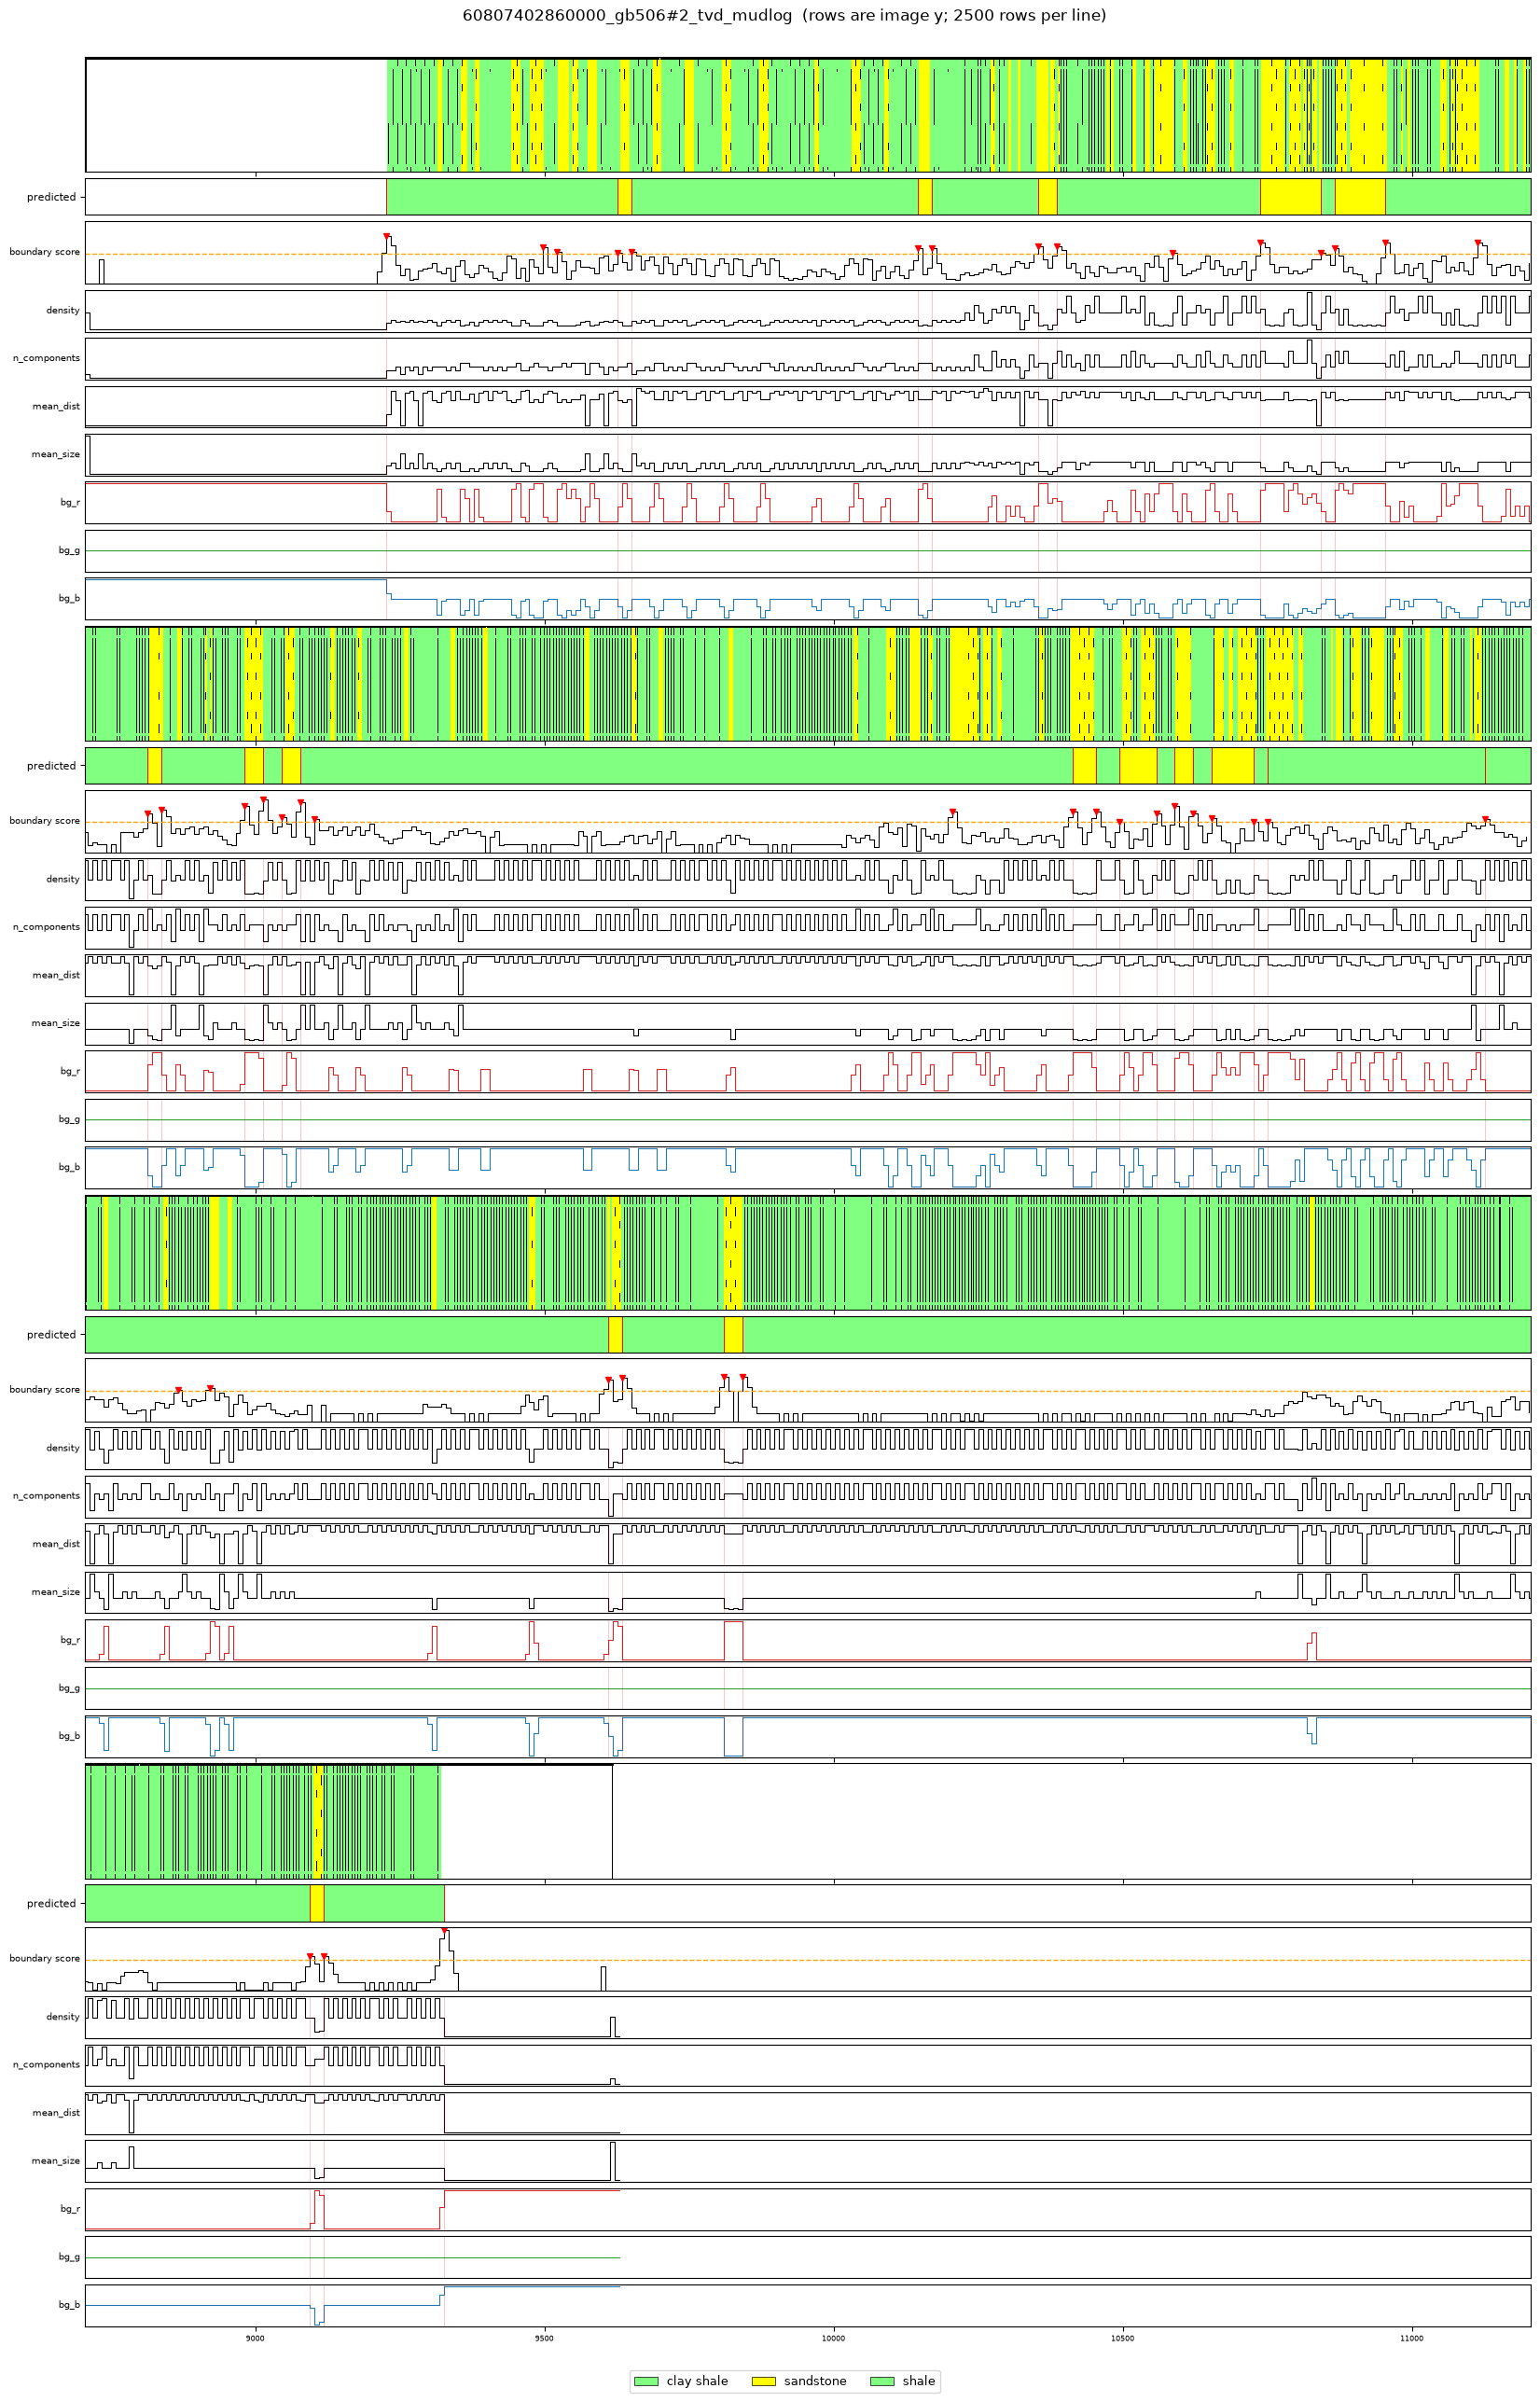

== Nichols 1 Mud Log
  1. column (4355, 183, 3), y offset 6473
  2. 48 segments


c:\Users\Benedek\!_Extr\HTB_final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [ ]:
# Pages to process (file stems under data/test/images). If GT_DIR/<stem>.json exists, the prediction is scored.
STEMS = sorted(
    p.stem
    for p in (ROOT / "test" / "images").iterdir()
    if p.suffix.lower() in (".tif", ".tiff", ".png")
)

summary = []
for stem in STEMS:
    print(f"== {stem}")
    res = run_pipeline(stem)  # steps 1-4: column, segments, legend, classification
    gt = load_gt(stem)
    if gt is None:
        print("  no ground truth -> metrics skipped")
    else:
        f1, n_gt, n_pred = boundary_f1(
            gt, pred_layers(res)
        )  # step 5: boundary F1 (segmentation)
        ious, miou, pix_acc = class_iou(
            gt, pred_layers(res)
        )  # step 5: IoU (classification)
        print(f"  boundaries: {n_gt} true / {n_pred} predicted")
        print(
            "  boundary F1  "
            + "   ".join(
                f"@{t}px: {v['f1']:.3f} (P {v['precision']:.2f} R {v['recall']:.2f})"
                for t, v in f1.items()
            )
        )
        print(f"  class IoU    mIoU {miou:.3f}   pixel accuracy {pix_acc:.3f}")
        for c, v in ious.items():
            print(
                f"    {c:<30} IoU {v['iou']:.3f}   true rows {v['gt_rows']:>6}   predicted rows {v['pred_rows']:>6}"
            )
        summary.append(dict(stem=stem, f1_5px=f1[5]["f1"], miou=miou))
    plot_page(res, gt)  # step 6: columns + predictions, several lines
if summary:
    print(pd.DataFrame(summary).set_index("stem").round(3))


## 7. Batch evaluation against ground truth

Runs the pipeline on every page that has a label file in `GT_DIR`, then reports boundary precision / recall / F1 and class IoU per page and aggregated over the batch (micro = pooled boundaries and pixels, macro = mean of per-page scores). CSVs are written to `OUTPUT_DIR/eval`.

In [ ]:
# Pages to evaluate: every page that has both an image + bbox annotation and a ground-truth file with layers in GT_DIR.
# Set EVAL_STEMS to an explicit list to override, or MAX_PAGES to cap the batch.
EVAL_STEMS = None
MAX_PAGES = None
TOLS = (3, 5, 10)


# External pages whose truth is unrealistic are excluded: single-bed pages (Flat Bay p071/p073/p075)
# and the thin-bed Idaho Barlow3-14 pages (hundreds of 2-5 px beds, many ambiguous-alias intervals)
EXT_EXCLUDE = {
    "ext_nl_flat-bay-2_p071",
    "ext_nl_flat-bay-2_p073",
    "ext_nl_flat-bay-2_p075",
    "ext_idaho_barlow3-14_p001",
    "ext_idaho_barlow3-14_p002",
}


def discover_eval_stems():
    stems = []
    for p in sorted((EXT_DIR / "truth").glob("*.csv")):
        if p.stem not in EXT_EXCLUDE and load_gt(p.stem):
            stems.append(p.stem)
    for p in sorted(GT_DIR.glob("*.json")):
        try:
            page_paths(p.stem)
        except FileNotFoundError:
            continue
        if load_gt(p.stem):
            stems.append(p.stem)
    return stems


# Pixel-wise intersection / union per class (counts, so they can be pooled over pages)
def class_counts(gt, pred):
    lo = min(l[0] for l in gt + pred)
    hi = max(l[1] for l in gt + pred)
    g, p = rows_by_name(gt, lo, hi), rows_by_name(pred, lo, hi)
    out = {}
    for c in (set(g) | set(p)) - {"background"}:
        out[c] = dict(
            inter=int(((g == c) & (p == c)).sum()),
            union=int(((g == c) | (p == c)).sum()),
            gt_rows=int((g == c).sum()),
            pred_rows=int((p == c).sum()),
        )
    return out, int((g == p).sum()), int(len(g))


def evaluate_page(stem):
    res = run_pipeline(stem, verbose=False)
    gt, pred = load_gt(stem), pred_layers(res)
    if (EXT_DIR / "truth" / f"{stem}.csv").exists():
        # external truth leaves gaps (e.g. before the first labelled bed): score only inside its span
        lo, hi = min(l[0] for l in gt), max(l[1] for l in gt)
        pred = [(max(a, lo), min(b, hi), n) for a, b, n in pred if b > lo and a < hi]
    g, p = boundary_set(gt), boundary_set(pred)
    row = dict(stem=stem, n_gt_boundaries=len(g), n_pred_boundaries=len(p))
    for t in TOLS:  # raw counts are kept so the batch can be pooled (micro average)
        row[f"tp_{t}"] = boundary_match(g, p, t)
    counts, correct_rows, total_rows = class_counts(gt, pred)
    row.update(correct_rows=correct_rows, total_rows=total_rows)
    ious, miou, pix_acc = class_iou(gt, pred)
    row.update(miou=miou, pixel_acc=pix_acc)
    return row, counts


stems = EVAL_STEMS or discover_eval_stems()
if MAX_PAGES:
    stems = stems[:MAX_PAGES]
print(f"{len(stems)} pages with ground truth")

page_rows, class_rows, failed = [], [], []
for i, stem in enumerate(stems, 1):
    print(f"[{i}/{len(stems)}] {stem}")
    try:
        row, counts = evaluate_page(stem)
    except Exception as e:  # keep the batch going; failures are reported below
        print(f"   FAILED: {type(e).__name__}: {e}")
        failed.append(dict(stem=stem, error=f"{type(e).__name__}: {e}"))
        continue
    page_rows.append(row)
    class_rows += [dict(stem=stem, cls=c, **v) for c, v in counts.items()]
    print(
        f"   boundary F1@5px "
        f"{2 * row['tp_5'] / max(row['n_gt_boundaries'] + row['n_pred_boundaries'], 1):.3f}"
        f"   mIoU {row['miou']:.3f}   pixel acc {row['pixel_acc']:.3f}"
    )

2 pages with ground truth
[1/2] 60808400140000_hadrian 2_masterlog_2in_10000-21962


c:\Users\Benedek\!_Extr\HTB_final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


   boundary F1@5px 0.630   mIoU 0.715   pixel acc 0.923
[2/2] 60811405350100_shenzi-sb203-st00bp01_mudlog_4320-27400


c:\Users\Benedek\!_Extr\HTB_final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


   boundary F1@5px 0.442   mIoU 0.467   pixel acc 0.753


### Aggregate report

In [ ]:
pages = pd.DataFrame(page_rows)
classes = pd.DataFrame(class_rows)


def f1_from_counts(tp, n_gt, n_pred):
    pr, rc = tp / max(n_pred, 1), tp / max(n_gt, 1)
    return pr, rc, (2 * pr * rc / (pr + rc) if tp else 0.0)


if pages.empty:
    print("No page could be evaluated.")
else:
    # Per-page table
    for t in TOLS:
        pr, rc, f1 = zip(
            *[
                f1_from_counts(r[f"tp_{t}"], r.n_gt_boundaries, r.n_pred_boundaries)
                for _, r in pages.iterrows()
            ]
        )
        pages[f"P@{t}"], pages[f"R@{t}"], pages[f"F1@{t}"] = pr, rc, f1
    per_page = pages.set_index("stem")[
        ["n_gt_boundaries", "n_pred_boundaries"]
        + [f"F1@{t}" for t in TOLS]
        + ["miou", "pixel_acc"]
    ]
    print("== Per page")
    display(per_page.round(3))

    # Aggregate: micro = pool all boundaries / pixels, macro = mean of per-page scores
    agg = {}
    for t in TOLS:
        pr, rc, f1 = f1_from_counts(
            pages[f"tp_{t}"].sum(),
            pages.n_gt_boundaries.sum(),
            pages.n_pred_boundaries.sum(),
        )
        agg[f"boundary P@{t}px (micro)"] = pr
        agg[f"boundary R@{t}px (micro)"] = rc
        agg[f"boundary F1@{t}px (micro)"] = f1
        agg[f"boundary F1@{t}px (macro)"] = pages[f"F1@{t}"].mean()
    agg["pixel accuracy (micro)"] = pages.correct_rows.sum() / pages.total_rows.sum()
    agg["pixel accuracy (macro)"] = pages.pixel_acc.mean()
    agg["mIoU (macro over pages)"] = pages.miou.mean()

    # Class IoU pooled over the whole batch (classes that occur in the ground truth)
    by_class = classes.groupby("cls")[["inter", "union", "gt_rows", "pred_rows"]].sum()
    by_class["iou"] = by_class.inter / by_class.union
    by_class["n_pages_gt"] = classes[classes.gt_rows > 0].groupby("cls").stem.nunique()
    by_class = by_class.fillna({"n_pages_gt": 0})
    in_gt = by_class[by_class.gt_rows > 0]
    agg["mIoU (pooled classes)"] = in_gt.iou.mean()
    agg["mIoU (pooled classes, row-weighted)"] = (
        in_gt.iou * in_gt.gt_rows
    ).sum() / in_gt.gt_rows.sum()
    agg["pages evaluated / failed"] = f"{len(pages)} / {len(failed)}"

    print("\n== Aggregate over the batch")
    display(pd.Series(agg, name="value").to_frame().round(3))
    print("\n== Class IoU (pooled over pages), worst first")
    display(
        by_class.sort_values("iou")[
            ["iou", "gt_rows", "pred_rows", "n_pages_gt"]
        ].round(3)
    )
    if failed:
        print("\n== Failed pages")
        display(pd.DataFrame(failed))

    out = OUTPUT_DIR / "eval"
    out.mkdir(parents=True, exist_ok=True)
    per_page.to_csv(out / "per_page.csv")
    by_class.to_csv(out / "class_iou.csv")
    pd.Series(agg, name="value").to_csv(out / "aggregate.csv")
    print(f"\nsaved to {out}")

== Per page


,n_gt_boundaries,n_pred_boundaries,F1@3,F1@5,F1@10,miou,pixel_acc
stem,,,,,,,
60808400140000_hadrian 2_masterlog_2in_10000-21962,728,421,0.463,0.630,0.724,0.715,0.923
60811405350100_shenzi-sb203-st00bp01_mudlog_4320-27400,294,389,0.287,0.442,0.618,0.467,0.753



== Aggregate over the batch


,value
boundary P@3px (micro),0.449383
boundary R@3px (micro),0.356164
boundary F1@3px (micro),0.39738
boundary F1@3px (macro),0.37499
boundary P@5px (micro),0.633333
boundary R@5px (micro),0.501957
boundary F1@5px (micro),0.560044
boundary F1@5px (macro),0.53614
boundary P@10px (micro),0.774074
boundary R@10px (micro),0.613503



== Class IoU (pooled over pages), worst first


,iou,gt_rows,pred_rows,n_pages_gt
cls,,,,
chalk,0.000,0,232,0.0
clay,0.000,0,480,0.0
dolomitic limestone,0.000,0,384,0.0
gypsum,0.000,0,176,0.0
legend 22,0.000,0,27,0.0
legend 4,0.000,0,120,0.0
limestone,0.000,642,0,1.0
ore,0.000,0,25,0.0
volcanic,0.000,0,840,0.0



saved to c:\Users\Benedek\!_Extr\HTB_final\viridian402\data\predictions\eval
